<a href="https://colab.research.google.com/github/NagasaiSree/ML_LabActivity/blob/main/DecisionTreeClassifier_StayinOrGoOut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Training accuracy: 1.0


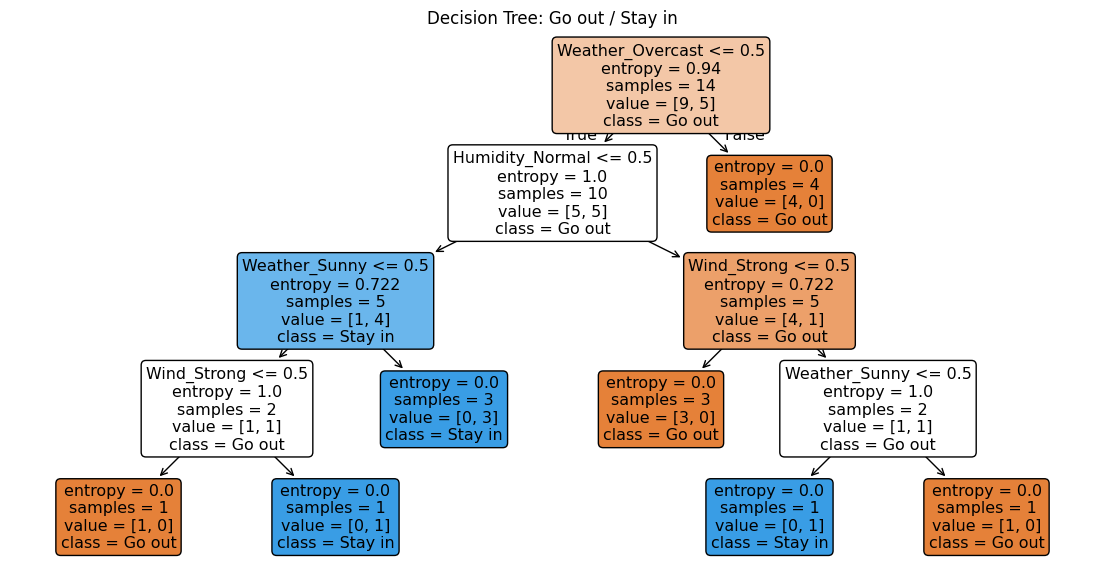

Prediction for new day: Go out


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

data = pd.DataFrame({
    'Weather':     ['Sunny','Sunny','Overcast','Rainy','Rainy','Rainy','Overcast','Sunny','Sunny','Rainy','Sunny','Overcast','Overcast','Rainy'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Decision':    ['Stay in','Stay in','Go out','Go out','Go out','Stay in','Go out','Stay in','Go out','Go out','Go out','Go out','Go out','Stay in']
})
X = pd.get_dummies(data.drop(columns='Decision'))
y = data['Decision']

dt = DecisionTreeClassifier(criterion='entropy', random_state=5)
dt.fit(X, y)
print('Training accuracy:', dt.score(X, y))

plt.figure(figsize=(14, 7))
plot_tree(dt, feature_names=X.columns, class_names=dt.classes_, filled=True, rounded=True)
plt.title('Decision Tree: Go out / Stay in')
plt.show()

# Predict a new day: Sunny, Mild, Normal humidity, Weak wind
new_day = pd.DataFrame([{'Weather':'Sunny','Temperature':'Mild','Humidity':'Normal','Wind':'Weak'}])
new_X = pd.get_dummies(new_day).reindex(columns=X.columns, fill_value=0)
print('Prediction for new day:', dt.predict(new_X)[0])